# 08 · AI2: spotting high-value customers from their first order

**The business question, simply:** the moment a new customer places their first order, can we tell
whether they will become valuable? If yes, the team can spend retention effort (a welcome call,
a sample pack, a better offer) on the right people instead of on everyone.

**Definition:** a *high-value* customer is in the top 25% of contribution earned in their first
12 months (first order included).

**Rules that keep this honest:**
- Only information known **at the first order** is used.
- **Time-based split:** train on customers acquired in weeks 1–39, test on those acquired in weeks
  40–52. The model is judged on customers it has never seen, from a later period, as in real use.
- Each test customer is followed for a full 12 months, which the data allows up to week 52.

**Why not a churn model?** The Revenue Pipeline capstone already has one. This model supports a
different decision: where to invest in new customers.

In [ ]:
# Colab set-up: run this first (skipped automatically outside Colab)
import sys, os
if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/anvesha2402/prakriti-growth-measurement.git"   # change if your repo differs
    if not os.path.exists("/content/repo"):
        get_ipython().system(f"git clone {REPO_URL} /content/repo")
    os.chdir("/content/repo")
    get_ipython().system("pip install -q 'pymc-marketing==1.1.*' statsmodels h5netcdf")


In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else "src")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, precision_recall_curve
from sklearn.calibration import calibration_curve
from common import FULL, COLOR, INK, INK2, NEUTRAL, style, save, ROOT

style()
START = pd.Timestamp("2024-10-07")
cust = pd.read_csv(FULL / "customers.csv", parse_dates=["first_order_date"])
orders = pd.read_csv(FULL / "orders.csv", parse_dates=["date"])
cust["acq_week"] = (cust.first_order_date - START).dt.days // 7 + 1
cust = cust[cust.acq_week <= 52].copy()                     # needs 12 months of follow-up

## 1. Build the label and the first-order features

In [2]:
o = orders.merge(cust[["customer_id", "first_order_date"]])
o = o[o.date < o.first_order_date + pd.Timedelta(days=365)]
value12 = o.groupby("customer_id")["contribution_inr"].sum()
first = orders.sort_values("date").groupby("customer_id").first()
cust = cust.set_index("customer_id")
cust["value_12m"] = value12
cust["first_value"] = first["gross_value_inr"]
cust["first_discount_share"] = first["discount_inr"] / first["gross_value_inr"]
cust["first_contribution"] = first["contribution_inr"]
cust["month"] = cust.first_order_date.dt.month.astype(str)
cust["weekday"] = cust.first_order_date.dt.dayofweek.astype(str)
cut = cust["value_12m"].quantile(0.75)
cust["high_value"] = (cust["value_12m"] >= cut).astype(int)
print(f"{len(cust):,} customers; high-value threshold = ₹{cut:.0f} contribution in 12 months; "
      f"{cust.high_value.mean():.0%} positive")

NUM = ["first_value", "first_discount_share", "first_contribution"]
CAT = ["acquisition_channel", "geo", "month", "weekday"]
train, test = cust[cust.acq_week <= 39], cust[cust.acq_week >= 40]
print(f"Train: {len(train):,} (weeks 1–39) | Test: {len(test):,} (weeks 40–52)")

14,876 customers; high-value threshold = ₹834 contribution in 12 months; 25% positive
Train: 10,667 (weeks 1–39) | Test: 4,209 (weeks 40–52)


## 2. Three models, from simple to complex

In [3]:
prep = ColumnTransformer([("num", StandardScaler(), NUM),
                          ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
models = {
    "Logistic regression": LogisticRegression(max_iter=2000, C=1.0),
    "Random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=20, random_state=7, n_jobs=-1),
    "Gradient boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, min_samples_leaf=40, random_state=7),
}
res, probs = [], {}
for name, m in models.items():
    pipe = Pipeline([("prep", prep), ("model", m)]).fit(train[NUM + CAT], train.high_value)
    p = pipe.predict_proba(test[NUM + CAT])[:, 1]
    probs[name] = (pipe, p)
    res.append(dict(model=name, PR_AUC=average_precision_score(test.high_value, p),
                    ROC_AUC=roc_auc_score(test.high_value, p), Brier=brier_score_loss(test.high_value, p)))
res = pd.DataFrame(res).set_index("model")
print(f"A random guess scores PR-AUC = {test.high_value.mean():.2f} (the share of positives).")
res.round(3)

A random guess scores PR-AUC = 0.26 (the share of positives).


,PR_AUC,ROC_AUC,Brier
model,,,
Logistic regression,0.534,0.768,0.159
Random forest,0.533,0.767,0.158
Gradient boosting,0.520,0.762,0.160


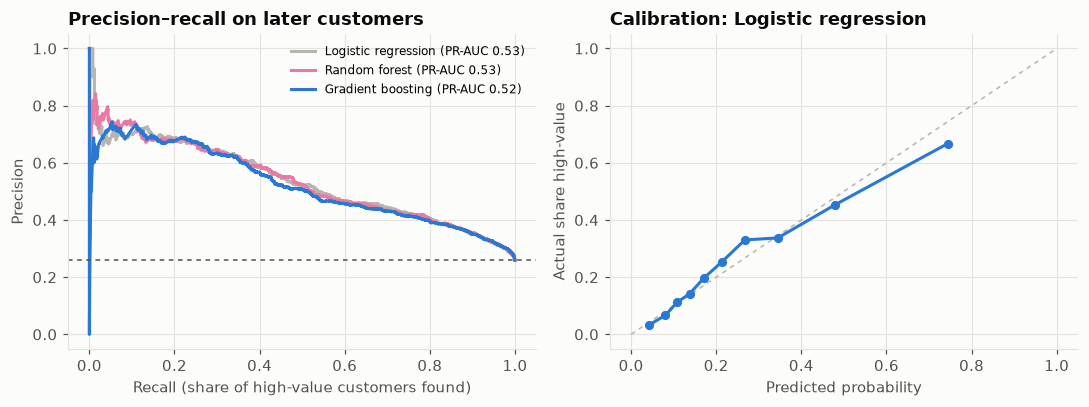

In [4]:
best = res.PR_AUC.idxmax()
pipe, p = probs[best]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for (name, (_, pp)), col in zip(probs.items(), [NEUTRAL, COLOR["youtube"], COLOR["meta"]]):
    pr, rc, _ = precision_recall_curve(test.high_value, pp)
    axes[0].plot(rc, pr, color=col, label=f"{name} (PR-AUC {res.loc[name, 'PR_AUC']:.2f})")
axes[0].axhline(test.high_value.mean(), color=INK2, lw=1, ls=(0, (3, 3)))
axes[0].set_xlabel("Recall (share of high-value customers found)"); axes[0].set_ylabel("Precision")
axes[0].legend(frameon=False, fontsize=8); axes[0].set_title("Precision–recall on later customers")
frac, mean_pred = calibration_curve(test.high_value, p, n_bins=10, strategy="quantile")
axes[1].plot([0, 1], [0, 1], color=NEUTRAL, lw=1, ls=(0, (3, 3)))
axes[1].plot(mean_pred, frac, "o-", color=COLOR["meta"], ms=5)
axes[1].set_xlabel("Predicted probability"); axes[1].set_ylabel("Actual share high-value")
axes[1].set_title(f"Calibration: {best}")
fig.tight_layout(); save(fig, "08_pr_and_calibration"); plt.show()

## 3. What drives the prediction? (SHAP)
SHAP splits each prediction into the push from each feature. The question to check: does the
acquisition channel matter **beyond** order value and discount?

Background dataset has 300 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=300 when initializing the masker.


PermutationExplainer explainer:  31%|███       | 463/1500 [00:00<?, ?it/s]

PermutationExplainer explainer:  31%|███▏      | 470/1500 [00:10<00:15, 68.42it/s]

PermutationExplainer explainer:  32%|███▏      | 477/1500 [00:10<00:17, 60.18it/s]

PermutationExplainer explainer:  32%|███▏      | 484/1500 [00:10<00:16, 62.54it/s]

...

PermutationExplainer explainer:  98%|█████████▊| 1477/1500 [00:27<00:00, 59.51it/s]

PermutationExplainer explainer:  99%|█████████▉| 1484/1500 [00:27<00:00, 55.89it/s]

PermutationExplainer explainer:  99%|█████████▉| 1490/1500 [00:27<00:00, 53.82it/s]

PermutationExplainer explainer: 100%|█████████▉| 1496/1500 [00:27<00:00, 51.97it/s]

PermutationExplainer explainer: 1501it [00:27, 37.45it/s]                          

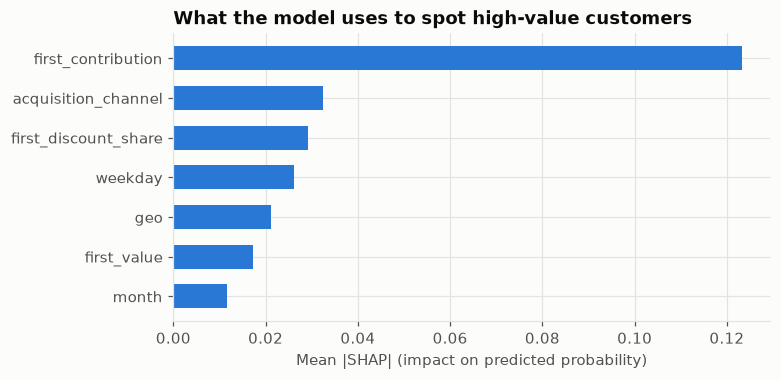

first_contribution      0.1232
acquisition_channel     0.0324
first_discount_share    0.0292
weekday                 0.0261
geo                     0.0212
first_value             0.0172
month                   0.0116
dtype: float64

In [5]:
import shap
X_test = pipe.named_steps["prep"].transform(test[NUM + CAT])
names = pipe.named_steps["prep"].get_feature_names_out()
sample = X_test[np.random.default_rng(1).choice(len(X_test), min(1500, len(X_test)), replace=False)]
model = pipe.named_steps["model"]
explainer = shap.Explainer(model.predict_proba if best == "Logistic regression" else model,
                           X_test[:300] if best == "Logistic regression" else None)
sv = explainer(sample)
vals = sv.values[..., 1] if sv.values.ndim == 3 else sv.values
imp = pd.Series(np.abs(vals).mean(0), index=names)
def base_feature(n):
    raw = n.split("__", 1)[1]
    return next((c for c in CAT if raw.startswith(c + "_")), raw) if n.startswith("cat__") else raw
group = imp.groupby(base_feature).sum()
group = group.sort_values()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(group.index, group.values, color=COLOR["meta"], height=0.6)
ax.set_xlabel("Mean |SHAP| (impact on predicted probability)")
ax.set_title("What the model uses to spot high-value customers")
save(fig, "08_shap_importance"); plt.show()
group.sort_values(ascending=False).round(4)

## 4. Pick the cut-off on a profit curve, not at 0.5
**Assumptions (stated, not hidden):**
- Treating a customer as high-value costs **₹120** (sample pack + welcome call).
- For a true high-value customer it protects about **₹300** of extra 12-month contribution.

Expected profit = true positives × ₹300 − false positives × ₹120 (scaled ×8 for the full customer base).

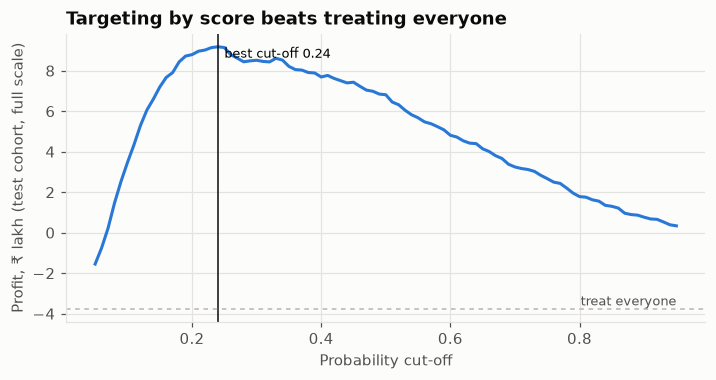

Best cut-off 0.24: target 39% of new customers, precision 45%, recall 68%, profit ₹9.2 lakh vs ₹-3.7 lakh treating everyone


In [6]:
GAIN, COST = 300, 120
th = np.linspace(0.05, 0.95, 91)
y = test.high_value.values
profit = np.array([((p >= t) & (y == 1)).sum() * GAIN - ((p >= t) & (y == 0)).sum() * COST for t in th]) * 8
t_best = th[profit.argmax()]
everyone = (y.sum() * GAIN - (1 - y).sum() * COST) * 8
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(th, profit / 1e5, color=COLOR["meta"])
ax.axvline(t_best, color=INK, lw=1); ax.axhline(everyone / 1e5, color=NEUTRAL, ls=(0, (3, 3)), lw=1)
ax.text(t_best + 0.01, profit.max() / 1e5, f"best cut-off {t_best:.2f}", va="top", fontsize=8.5)
ax.text(0.95, everyone / 1e5, "treat everyone", ha="right", va="bottom", fontsize=8.5, color=INK2)
ax.set_xlabel("Probability cut-off"); ax.set_ylabel("Profit, ₹ lakh (test cohort, full scale)")
ax.set_title("Targeting by score beats treating everyone")
save(fig, "08_profit_curve"); plt.show()
sel = p >= t_best
print(f"Best cut-off {t_best:.2f}: target {sel.mean():.0%} of new customers, precision {y[sel].mean():.0%}, "
      f"recall {y[sel].sum() / y.sum():.0%}, profit ₹{profit.max() / 1e5:.1f} lakh vs ₹{everyone / 1e5:.1f} lakh treating everyone")

## 5. Fairness check by city
Does the model favour some cities? Compare who gets targeted and how accurate it is, city by city.

In [7]:
fair = pd.DataFrame({"geo": test.geo.values, "y": y, "sel": sel}).groupby("geo").apply(
    lambda d: pd.Series({"customers": len(d), "actual high-value rate": d.y.mean(), "targeted rate": d.sel.mean(),
                         "precision": d.y[d.sel].mean() if d.sel.any() else np.nan,
                         "recall": d.sel[d.y == 1].mean() if (d.y == 1).any() else np.nan}), include_groups=False)
fair.round(2)

,customers,actual high-value rate,targeted rate,precision,recall
geo,,,,,
Ahmedabad,304.0,0.26,0.34,0.52,0.68
Bengaluru,732.0,0.25,0.44,0.40,0.71
Chennai,443.0,0.26,0.39,0.42,0.62
Delhi NCR,818.0,0.25,0.38,0.45,0.66
Hyderabad,393.0,0.24,0.40,0.41,0.68
Kolkata,352.0,0.26,0.38,0.52,0.74
Mumbai,778.0,0.28,0.40,0.48,0.70
Pune,389.0,0.25,0.39,0.45,0.69


## 6. Cross-check with the CLV models (notebook 05)
Average model score by acquisition channel should rank channels like the BG/NBD CLV does.

In [8]:
clv = pd.read_csv(ROOT / "model" / "clv_by_channel.csv", index_col=0)
lab = {"Meta": "meta", "Google Search": "search", "YouTube": "youtube", "Influencers": "influencer",
       "Trade promotions": "trade_promo", "Organic": "organic"}
score_by_ch = pd.Series(p, index=test.index).groupby(test.acquisition_channel).mean()
both = pd.DataFrame({"mean score": score_by_ch, "CLV 24m ₹": clv["CLV 24m ₹"].rename(index=lab)}).dropna()
rho = spearmanr(both["mean score"], both["CLV 24m ₹"]).correlation
print(f"Spearman rank agreement, model score vs BG/NBD CLV by channel: {rho:.2f}")
both.round(3)

Spearman rank agreement, model score vs BG/NBD CLV by channel: 1.00


,mean score,CLV 24m ₹
influencer,0.309,1034.648
meta,0.198,717.093
organic,0.280,842.515
search,0.270,831.036
trade_promo,0.048,429.668
youtube,0.286,909.709


## 7. So what

In [9]:
ch_imp = group.get("acquisition_channel", 0)
rank_ch = group.sort_values(ascending=False).index.get_loc("acquisition_channel") + 1
print("SO WHAT")
print(f"1. The best model ({best}) finds high-value customers at PR-AUC {res.loc[best, 'PR_AUC']:.2f} "
      f"vs {test.high_value.mean():.2f} for guessing, on customers from a later period.")
print(f"2. Targeting the top {sel.mean():.0%} of scores earns ₹{profit.max() / 1e5:.1f} lakh on this cohort vs "
      f"₹{everyone / 1e5:.1f} lakh treating everyone (assumed ₹{GAIN} gain / ₹{COST} cost).")
print(f"3. Drivers (SHAP): first-order contribution leads; acquisition channel ranks #{rank_ch} of {len(group)}, "
      "so where a customer came from carries information beyond order value and discount.")
hi_city, lo_city = fair["targeted rate"].idxmax(), fair["targeted rate"].idxmin()
print(f"4. Checks: the model ranks channels like BG/NBD CLV (Spearman {rho:.2f}). Fairness by city: targeted rate ranges "
      f"{fair['targeted rate'].min():.0%} ({lo_city}) to {fair['targeted rate'].max():.0%} ({hi_city}) while actual high-value rates "
      f"stay within {fair['actual high-value rate'].min():.0%}–{fair['actual high-value rate'].max():.0%}. {hi_city} is over-targeted "
      f"(precision {fair.loc[hi_city, 'precision']:.0%}): monitor this, and consider a city-level cut-off if it persists.")

SO WHAT
1. The best model (Logistic regression) finds high-value customers at PR-AUC 0.53 vs 0.26 for guessing, on customers from a later period.
2. Targeting the top 39% of scores earns ₹9.2 lakh on this cohort vs ₹-3.7 lakh treating everyone (assumed ₹300 gain / ₹120 cost).
3. Drivers (SHAP): first-order contribution leads; acquisition channel ranks #2 of 7, so where a customer came from carries information beyond order value and discount.
4. Checks: the model ranks channels like BG/NBD CLV (Spearman 1.00). Fairness by city: targeted rate ranges 34% (Ahmedabad) to 44% (Bengaluru) while actual high-value rates stay within 24%–28%. Bengaluru is over-targeted (precision 40%): monitor this, and consider a city-level cut-off if it persists.
